In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from network_SIR import load_socio, make_network, network_stats, run_many, NET_COLORS

In [2]:
G_socio = load_socio()

n = G_socio.number_of_nodes()
m = G_socio.number_of_edges()
print("nodes:", n)
print("edges:", m)
print("average degree:", 2 * m / n)
print("connected components:", nx.number_connected_components(G_socio))
print("largest component:", len(max(nx.connected_components(G_socio), key=len)))

nodes: 374
edges: 1265
average degree: 6.764705882352941
connected components: 19
largest component: 354


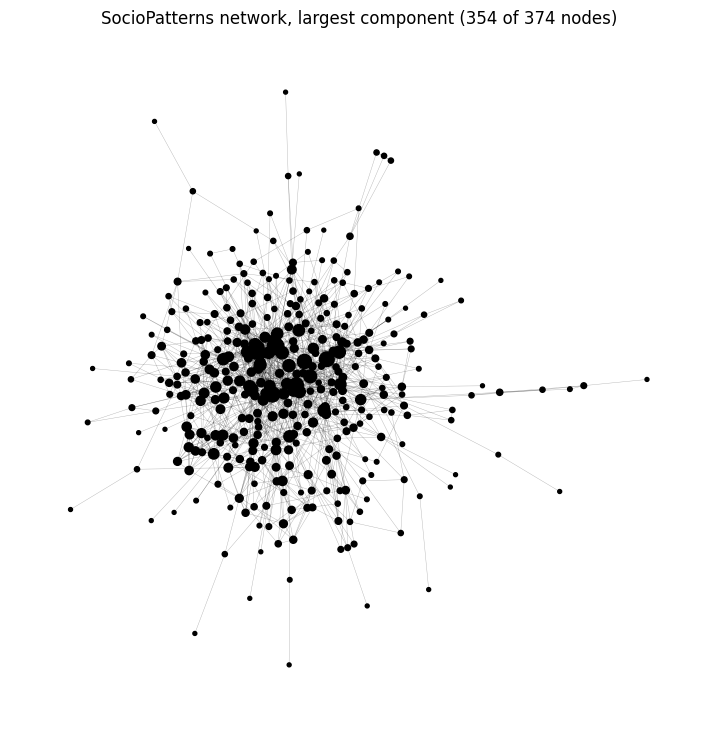

In [6]:
degrees = np.array([d for node, d in G_socio.degree()])

giant_nodes = max(nx.connected_components(G_socio), key=len)
G_giant = G_socio.subgraph(giant_nodes)
giant_degrees = np.array([d for node, d in G_giant.degree()])

pos = nx.spring_layout(G_giant, seed=1, k=0.15, iterations=200)

plt.figure(figsize=(9, 9))
nx.draw_networkx_edges(G_giant, pos, width=0.3, alpha=0.3)
nx.draw_networkx_nodes(G_giant, pos, node_size=5 + 3 * giant_degrees, node_color="black")
plt.title(f"SocioPatterns network, largest component ({G_giant.number_of_nodes()} of {n} nodes)")
plt.axis("off")
plt.savefig("figures/socio_network.png", dpi=200, bbox_inches="tight")
plt.show()

In [4]:
rows = []
for kind in ["ER", "WS", "BA"]:
    for i in range(10):
        stats = network_stats(make_network(kind, n, 6, seed=i))
        stats["type"] = kind
        rows.append(stats)

stats = network_stats(G_socio)
stats["type"] = "Socio"
rows.append(stats)

df = pd.DataFrame(rows)
df.groupby("type").mean().round(3)

,avg degree,max degree,<k^2>/<k>,clustering,avg path length,max betweenness,max closeness
type,,,,,,,
BA,5.952,59.4,12.334,0.063,3.119,0.191,0.486
ER,6.099,15.0,7.038,0.017,3.479,0.032,0.340
Socio,6.765,47.0,12.942,0.296,3.364,0.117,0.407
WS,6.000,8.7,6.102,0.440,5.065,0.058,0.238


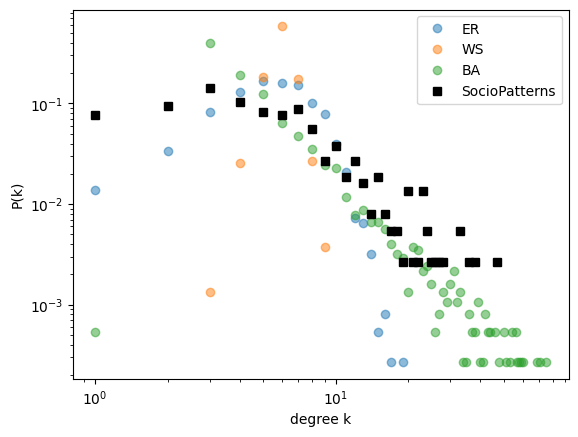

In [5]:
for kind in ["ER", "WS", "BA"]:
    deg = []
    for i in range(10):
        deg += [d for node, d in make_network(kind, n, 6, seed=i).degree()]
    values, counts = np.unique(deg, return_counts=True)
    plt.loglog(values, counts / len(deg), "o", color=NET_COLORS[kind], alpha=0.5, label=kind)

values, counts = np.unique(degrees, return_counts=True)
plt.loglog(values, counts / len(degrees), "s", color="black", label="SocioPatterns")

plt.xlabel("degree k")
plt.ylabel("P(k)")
plt.legend()
plt.savefig("figures/socio_degree_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

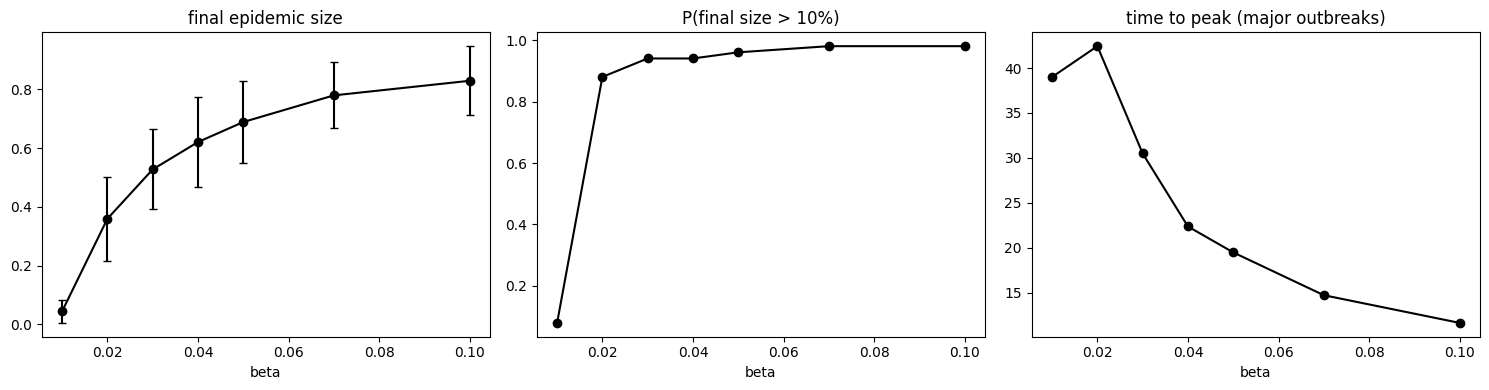

beta=0.01: final size=0.04, P(major)=0.08, t_peak=39
beta=0.02: final size=0.36, P(major)=0.88, t_peak=42
beta=0.03: final size=0.53, P(major)=0.94, t_peak=30
beta=0.04: final size=0.62, P(major)=0.94, t_peak=22
beta=0.05: final size=0.69, P(major)=0.96, t_peak=19
beta=0.07: final size=0.78, P(major)=0.98, t_peak=15
beta=0.1: final size=0.83, P(major)=0.98, t_peak=12


In [8]:
betas = [0.01, 0.02, 0.03, 0.04, 0.05, 0.07, 0.1]
gamma = 0.1

mean_final = []
std_final = []
p_major = []
mean_tpeak = []

for beta in betas:
    results = run_many(G_socio, beta, gamma, n_init=5, n_runs=50)
    finals = np.array([R[-1] for S, I, R in results])
    mean_final.append(np.mean(finals))
    std_final.append(np.std(finals))
    p_major.append(np.mean(finals > 0.1))
    mean_tpeak.append(np.mean([np.argmax(I) for S, I, R in results if R[-1] > 0.1]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].errorbar(betas, mean_final, yerr=std_final, marker="o", capsize=3, color="black")
axes[0].set_title("final epidemic size")
axes[1].plot(betas, p_major, marker="o", color="black")
axes[1].set_title("P(final size > 10%)")
axes[2].plot(betas, mean_tpeak, marker="o", color="black")
axes[2].set_title("time to peak (major outbreaks)")
for ax in axes:
    ax.set_xlabel("beta")
plt.tight_layout()
plt.savefig("figures/socio_beta_sweep.png", dpi=200, bbox_inches="tight")
plt.show()

for b, f, p, t in zip(betas, mean_final, p_major, mean_tpeak):
    print(f"beta={b}: final size={f:.2f}, P(major)={p:.2f}, t_peak={t:.0f}")